### imports

In [ ]:
import os
# import transformers
import numpy as np

from tqdm import tqdm
from typing import Union, List, Tuple
from sentencepiece import SentencePieceTrainer, SentencePieceProcessor
from sklearn.model_selection import train_test_split

import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset
import matplotlib.pyplot as plt

### tokenization & dataset

In [ ]:
class TextDataset(Dataset):
    TRAIN_VAL_RANDOM_SEED = 42
    VAL_RATIO = 0.05

    def __init__(self, data_file: str, train: bool = True, sp_model_prefix: str = None,
                 vocab_size: int = 2000, normalization_rule_name: str = 'nmt_nfkc_cf',
                 model_type: str = 'bpe', max_length: int = 128):
        """
        Dataset with texts, supporting BPE tokenizer
        :param data_file: txt file containing texts
        :param train: whether to use train or validation split
        :param sp_model_prefix: path prefix to save tokenizer model
        :param vocab_size: sentencepiece tokenizer vocabulary size
        :param normalization_rule_name: sentencepiece tokenizer normalization rule
        :param model_type: sentencepiece tokenizer model type
        :param max_length: maximal length of text in tokens
        """
        if not os.path.isfile(sp_model_prefix + '.model'):
            assert train
            # train tokenizer if not trained yet
            SentencePieceTrainer.train(
                input=data_file, vocab_size=vocab_size,
                model_type=model_type, model_prefix=sp_model_prefix,
                normalization_rule_name=normalization_rule_name,
                pad_id=3
            )
        # load tokenizer from filelogits.argmax(dim=2)
        self.sp_model = SentencePieceProcessor(model_file=sp_model_prefix + '.model')

        with open(data_file, encoding='utf-8') as file:
            texts = file.readlines()

        train_texts, val_texts = train_test_split(texts, test_size=self.VAL_RATIO, random_state=self.TRAIN_VAL_RANDOM_SEED)
        self.texts = train_texts if train else val_texts
        self.indices = self.sp_model.encode(self.texts)

        self.pad_id, self.unk_id, self.bos_id, self.eos_id = \
            self.sp_model.pad_id(), self.sp_model.unk_id(), \
            self.sp_model.bos_id(), self.sp_model.eos_id()
        self.max_length = max_length
        self.vocab_size = self.sp_model.vocab_size()

        self.indices = list(map(lambda x:
            [self.bos_id] + x[:self.max_length - 2] + [self.eos_id], self.indices))
        self.indices = list(map(lambda x:
            np.pad(x, (0, self.max_length - len(x)), constant_values=self.pad_id, mode='constant'), self.indices))

    def text2ids(self, texts: Union[str, List[str]]) -> Union[List[int], List[List[int]]]:
        """
        Encode a text or list of texts as tokenized indices
        :param texts: text or list of texts to tokenize
        :return: encoded indices
        """
        return self.sp_model.encode(texts)

    def ids2text(self, ids: Union[torch.Tensor, List[int], List[List[int]]]) -> Union[str, List[str]]:
        """
        Decode indices as a text or list of tokens
        :param ids: 1D or 2D list (or torch.Tensor) of indices to decode
        :return: decoded texts
        """
        if torch.is_tensor(ids):
            assert len(ids.shape) <= 2, 'Expected tensor of shape (length, ) or (batch_size, length)'
            ids = ids.cpu().tolist()

        return self.sp_model.decode(ids)

    def __len__(self):
        """
        Size of the dataset
        :return: number of texts in the dataset
        """
        return len(self.indices)

    def __getitem__(self, item: int) -> Tuple[torch.Tensor, int]:
        """
        Add specials to the index array and pad to maximal length
        :param item: text id
        :return: encoded text indices and its actual length (including BOS and EOS specials)
        """
        return self.indices[item], 0

In [ ]:
vocab_size = 4096
max_length = 128
sp_model_prefix = f'sentencepiece_bpe_{vocab_size}_{max_length}'
data_file = 'jokes.txt'

train_set = TextDataset(data_file=data_file, train=True, sp_model_prefix=sp_model_prefix, vocab_size=vocab_size, max_length=max_length)
valid_set = TextDataset(data_file=data_file, train=False, sp_model_prefix=sp_model_prefix, vocab_size=vocab_size, max_length=max_length)

In [ ]:
print(train_set.ids2text(train_set[2][0]))
train_set[2]

люди, которые делают утреннюю зарядку, умирают в сто раз реже остальных. потому что их в сто раз меньше, чем остальных.


(array([   1,  570, 4073,  801, 2443,  561,  535, 2669,   49, 1414,   80,
        4073, 3804,  121,    6,  252,  149,  178,  130,  400, 1739, 4071,
         471,   48,  408,    6,  252,  149, 1578, 4073,  304,  400, 1739,
        4071,    2,    3,    3,    3,    3,    3,    3,    3,    3,    3,
           3,    3,    3,    3,    3,    3,    3,    3,    3,    3,    3,
           3,    3,    3,    3,    3,    3,    3,    3,    3,    3,    3,
           3,    3,    3,    3,    3,    3,    3,    3,    3,    3,    3,
           3,    3,    3,    3,    3,    3,    3,    3,    3,    3,    3,
           3,    3,    3,    3,    3,    3,    3,    3,    3,    3,    3,
           3,    3,    3,    3,    3,    3,    3,    3,    3,    3,    3,
           3,    3,    3,    3,    3,    3,    3,    3,    3,    3,    3,
           3,    3,    3,    3,    3,    3,    3]),
 0)

### llm architecture

In [ ]:
class SwiGLUFFN(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.w1 = nn.Linear(dim, 4 * dim)
        self.w2 = nn.Linear(dim, 4 * dim)
        self.w3 = nn.Linear(4 * dim, dim)
        self.silu = nn.modules.activation.SiLU()

    def forward(self, x):
        return self.w3(self.silu(self.w1(x)) * (self.w2(x)))


class FeedForwardNetwork(nn.Module):
    def __init__(self, dim: int):
        super().__init__()
        self.c_fc = nn.Linear(dim, 4  * dim)
        self.gelu = nn.modules.activation.GELU()
        self.c_proj = nn.Linear(4 * dim, dim)

    def forward(self, x):
        # x.shape = [batch_size, seq_length, dim]
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


class MaskedSelfAttention(nn.Module):
    def __init__(self, dim: int, num_heads: int):
        super().__init__()
        self.c_attn = nn.Linear(dim, dim * 3)  # query + key + value, combined
        self.c_proj = nn.Linear(dim, dim)  # output projection
        self.dim = dim
        self.num_heads = num_heads
        self.head_size = dim // num_heads
        self.scale = self.head_size ** -0.5

    def forward(self, x):
        q, k, v = self.c_attn(x).split(dim=-1, split_size=self.dim)

        q = q.view(q.shape[0], q.shape[1], self.num_heads, self.head_size).transpose(1, 2)
        k = k.view(k.shape[0], k.shape[1], self.num_heads, self.head_size).transpose(1, 2)
        v = v.view(v.shape[0], v.shape[1], self.num_heads, self.head_size).transpose(1, 2)

        qk_t = q @ torch.transpose(k, 2, 3)

        # Apply the causal mask
        mask = torch.triu(torch.full(qk_t.shape, -torch.inf, device=x.device), diagonal=1)
        qk_t_masked = (qk_t + mask) * self.scale

        # Apply softmax to get attention probabilities
        attn_probs = torch.softmax(qk_t_masked, dim=-1)

        w_sum = attn_probs @ v

        c_embeds = torch.transpose(w_sum, 1, 2)
        c_embeds = c_embeds.reshape(c_embeds.shape[0], c_embeds.shape[1], self.dim)
        return self.c_proj(c_embeds)


class TransformerLayer(nn.Module):
    def __init__(self, dim: int, num_heads: int):
        super().__init__()
        # self.ln_1 = nn.LayerNorm(dim)
        self.rn_1 = nn.RMSNorm(dim)
        self.attn = MaskedSelfAttention(dim, num_heads)
        # self.ln_2 = nn.LayerNorm(dim)
        self.rn_2 = nn.RMSNorm(dim)
        self.mlp = SwiGLUFFN(dim)

    def forward(self, x):
        res = self.rn_1(x)
        res = self.attn(res)
        res += x
        x = res
        res = self.rn_2(res)
        res = self.mlp(res)
        res += x
        return res

In [ ]:
class GPT2(nn.Module):
    def __init__(self, vocab_size: int, dim: int, num_heads: int, num_layers: int, max_position_embeddings: int = 1024):
        super().__init__()
        self.wte = nn.Embedding(vocab_size, dim)               # token embeddings
        self.wpe = nn.Embedding(max_position_embeddings, dim)  # position embeddings
        self.ln_f = nn.LayerNorm(dim)                          # final layer norm - goes after all transformer layers, but before logits

        self.h = nn.Sequential(*(TransformerLayer(dim, num_heads) for layer in range(num_layers)))
        self.out = nn.Linear(dim, vocab_size)

    def forward(self, input_ids):
        # input_ids.shape: [batch_size, sequence_length], int64 token ids
        position_ids = torch.arange(input_ids.shape[1], device=input_ids.device).unsqueeze(0)

        token_embeddings = self.wte(input_ids)
        position_embeddings = self.wpe(position_ids)
        full_embeddings = token_embeddings + position_embeddings

        transformer_output = self.h(full_embeddings)
        transformer_output_ln = self.ln_f(transformer_output)

        # final layer: we predict logits by re-using token embeddings as linear weights
        # output_logits = transformer_output_ln @ self.wte.weight.T
        # final layer with untied embeddings: we predict logits by using separate projection layer
        output_logits = self.out(transformer_output_ln)
        return output_logits


#### check gpt 2

In [ ]:
from huggingface_hub import hf_hub_download
state_dict = torch.load(hf_hub_download("gpt2", filename="pytorch_model.bin"))
for key, value in tuple(state_dict.items()):
    if key.startswith('h.') and key.endswith('.weight') and value.ndim == 2:
        value.transpose_(1, 0)  # <-- for compatibility with modern PyTorch modules
    if key.startswith('h.') and key.endswith('.attn.bias') and value.ndim == 4:
        state_dict.pop(key)  # <-- triangular binar masks, not needed in this code

print('Weights:', repr(sorted(state_dict.keys()))[:320], '...')

Weights: ['h.0.attn.c_attn.bias', 'h.0.attn.c_attn.weight', 'h.0.attn.c_proj.bias', 'h.0.attn.c_proj.weight', 'h.0.ln_1.bias', 'h.0.ln_1.weight', 'h.0.ln_2.bias', 'h.0.ln_2.weight', 'h.0.mlp.c_fc.bias', 'h.0.mlp.c_fc.weight', 'h.0.mlp.c_proj.bias', 'h.0.mlp.c_proj.weight', 'h.1.attn.c_attn.bias', 'h.1.attn.c_attn.weight', 'h.1. ...


In [ ]:
tokenizer = transformers.AutoTokenizer.from_pretrained('gpt2', add_prefix_space=True)
model = GPT2(vocab_size=50257, dim=768, num_heads=12, num_layers=12).to(DEVICE)
model.load_state_dict(state_dict)

input_ids = tokenizer("A quick", return_tensors='pt')['input_ids'].to(DEVICE)

predicted_logits = model(input_ids)
print(predicted_logits.shape)
most_likely_token_id = predicted_logits[:, -1].argmax().item()

torch.Size([1, 2, 50257])


In [ ]:
text = "Your grandmother is"
tokens = tokenizer.encode(text)
print(end=tokenizer.decode(tokens))
line_length = len(tokenizer.decode(tokens))

for i in range(50):
    # Predict logits with your model
    with torch.no_grad():
        logits = model(torch.as_tensor([tokens]).to(DEVICE))

    # Sample with probabilities
    p_next = torch.softmax(logits[0, -1, :], dim=-1).data.cpu().numpy()
    next_token_index = np.random.choice(len(p_next), p=p_next)
    # next_token_index = np.argmax(p_next)

    tokens.append(int(next_token_index))
    print(end=tokenizer.decode(tokens[-1]))
    line_length += len(tokenizer.decode(tokens[-1]))
    if line_length > 120:
      line_length = 0
      print()

 Your grandmother is extremely loyal. And professed to love God and loved Pontius Pilate. But they regard him as having more
 authority than her, for Theombalis believe their children will change their views.

Everyton or petticoat is obviously

### training

In [ ]:
def plot_losses(train_losses: List[float], val_losses: List[float]):
    """
    Plot loss and perplexity of train and validation samples
    :param train_losses: list of train losses at each epoch
    :param val_losses: list of validation losses at each epoch
    """
    # clear_output()
    fig, axs = plt.subplots(1, 2, figsize=(13, 4))
    axs[0].plot(range(1, len(train_losses) + 1), train_losses, label='train')
    axs[0].plot(range(1, len(val_losses) + 1), val_losses, label='val')
    axs[0].set_ylabel('loss')

    train_perplexities, val_perplexities = torch.exp(torch.tensor(train_losses)), torch.exp(torch.tensor(val_losses))

    axs[1].plot(range(1, len(train_perplexities) + 1), train_perplexities, label='train')
    axs[1].plot(range(1, len(val_perplexities) + 1), val_perplexities, label='val')
    axs[1].set_ylabel('perplexity')

    for ax in axs:
        ax.set_xlabel('epoch')
        ax.legend()

    plt.show()


def training_epoch(model, optimizer, data_loader, criterion):
    model.train()
    device = next(model.parameters()).device
    train_loss = 0.0
    for batch in tqdm(data_loader, desc='training_epoch'):
        input_ids = batch[0].to(device)
        next_tokens = model(input_ids)

        true_next_tokens = input_ids[:, 1:]
        loss = criterion(
            next_tokens[:, :-1].transpose(1, 2),
            true_next_tokens
        )
        loss.backward()
        optimizer.step()
        optimizer.zero_grad(set_to_none=True)

        train_loss += loss.item()
    train_loss /= len(data_loader)
    return train_loss


def validation_epoch(model, data_loader, criterion):
    model.eval()
    device = next(model.parameters()).device
    val_loss = 0.0
    for batch in tqdm(data_loader, desc='validation_epoch'):
        input_ids = batch[0].to(device)
        with torch.no_grad():
            next_tokens = model(input_ids)
            true_next_tokens = input_ids[:, 1:]
            loss = criterion(
                next_tokens[:, :-1].transpose(1, 2),
                true_next_tokens
            )
        val_loss += loss.item()
    val_loss /= len(data_loader)
    return val_loss

In [ ]:
DEVICE = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
DEVICE

device(type='cuda')

In [ ]:
model = GPT2(vocab_size=vocab_size, dim=256, num_heads=8, num_layers=4, max_position_embeddings=1024)
model = model.to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
criterion = nn.modules.loss.CrossEntropyLoss(ignore_index=train_set.pad_id)
train_loader = torch.utils.data.DataLoader(
    train_set, batch_size=128, shuffle=True, num_workers=0,
)
val_loader = torch.utils.data.DataLoader(
    valid_set, batch_size=128, shuffle=True, num_workers=0,
)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(total_params)
train_losses = []
val_losses = []

6573568


epoch #5


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 14.30it/s]


['5.18', '4.27', '3.99', '3.82', '3.69']
['4.54', '4.12', '3.92', '3.78', '3.67']


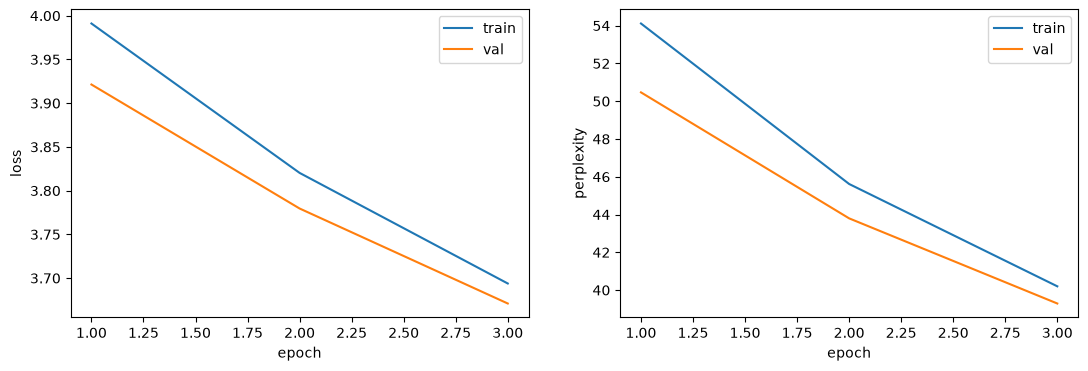

epoch #6


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 14.10it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58']


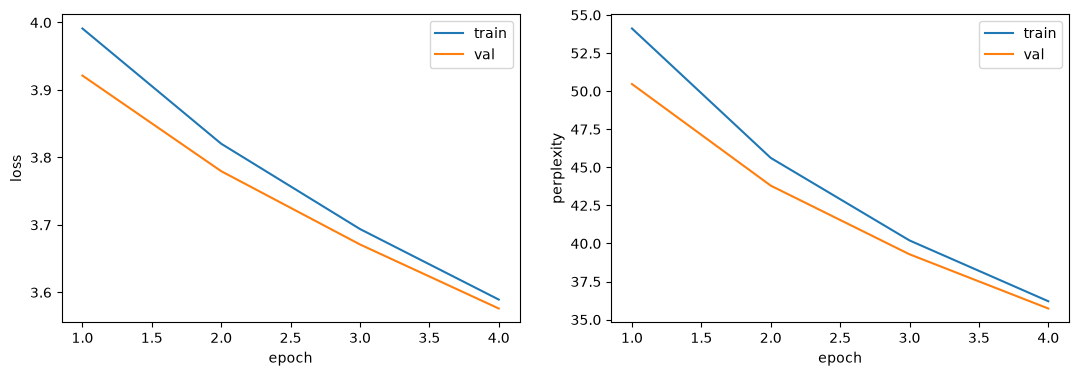

epoch #7


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 14.12it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49']


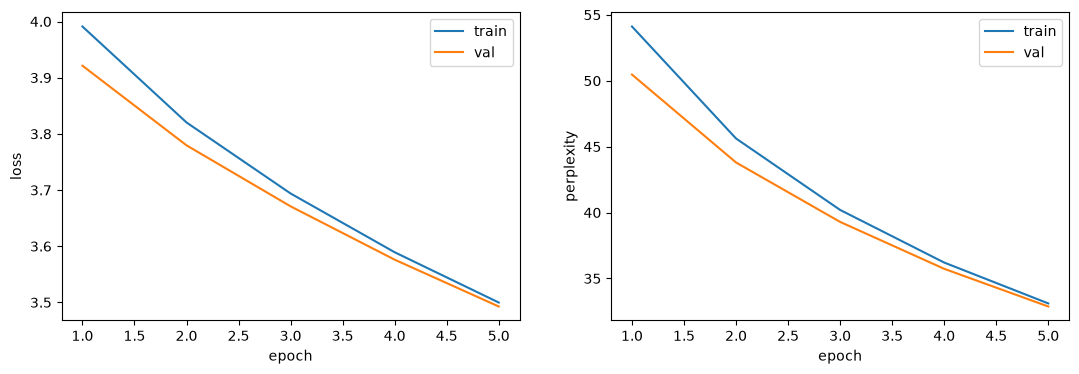

epoch #8


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 13.93it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50', '3.42']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49', '3.42']


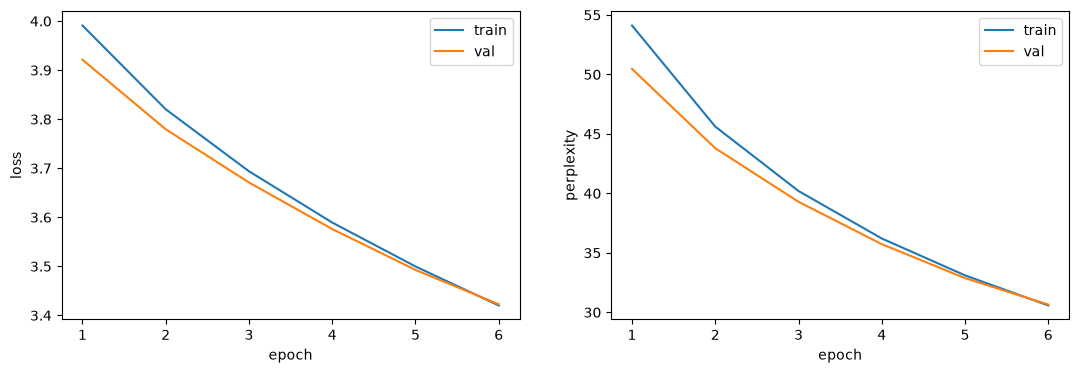

epoch #9


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 14.25it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50', '3.42', '3.35']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49', '3.42', '3.36']


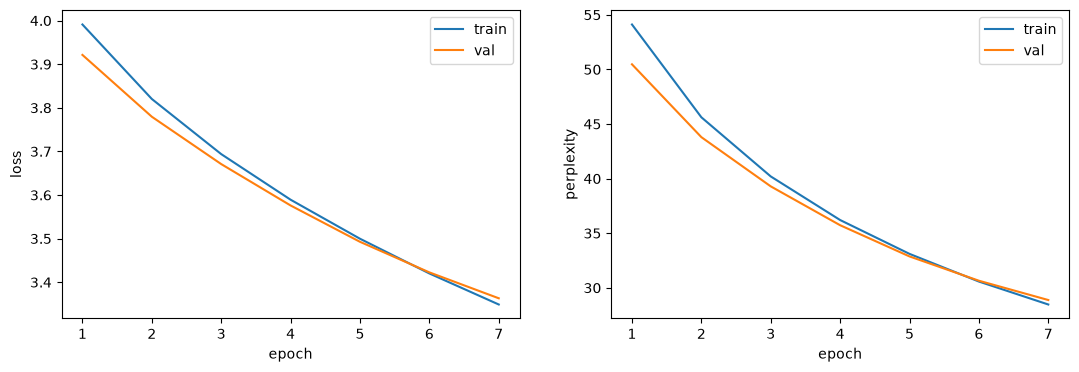

epoch #10


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 14.25it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50', '3.42', '3.35', '3.28']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49', '3.42', '3.36', '3.30']


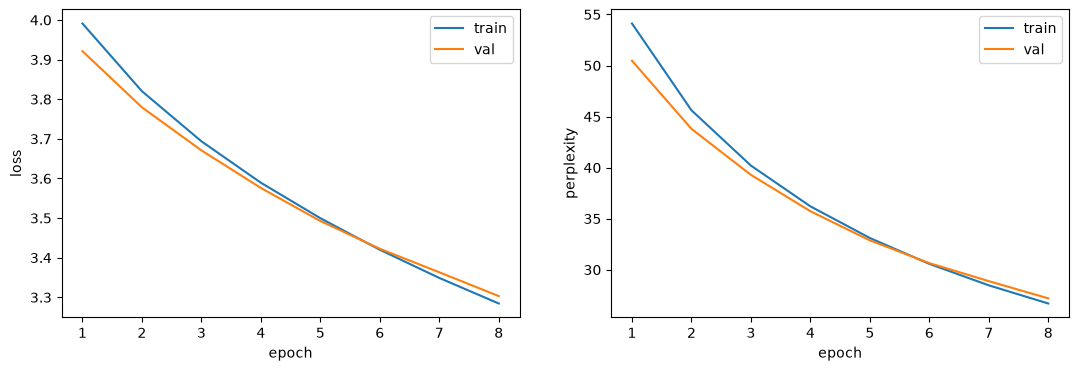

epoch #11


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 15.80it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50', '3.42', '3.35', '3.28', '3.22']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49', '3.42', '3.36', '3.30', '3.24']


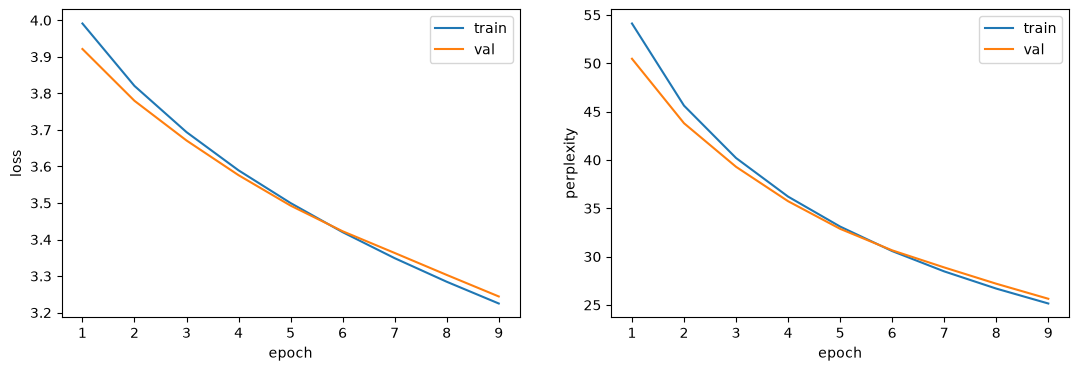

epoch #12


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 13.68it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50', '3.42', '3.35', '3.28', '3.22', '3.17']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49', '3.42', '3.36', '3.30', '3.24', '3.20']


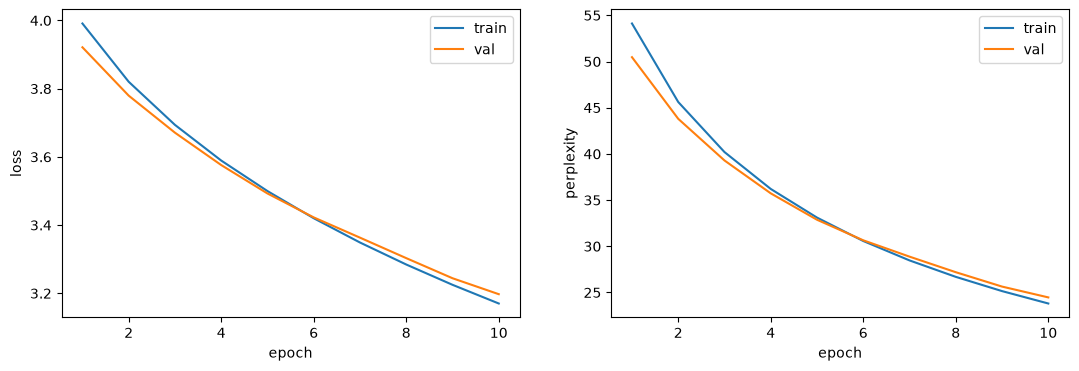

epoch #13


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 13.98it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50', '3.42', '3.35', '3.28', '3.22', '3.17', '3.12']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49', '3.42', '3.36', '3.30', '3.24', '3.20', '3.15']


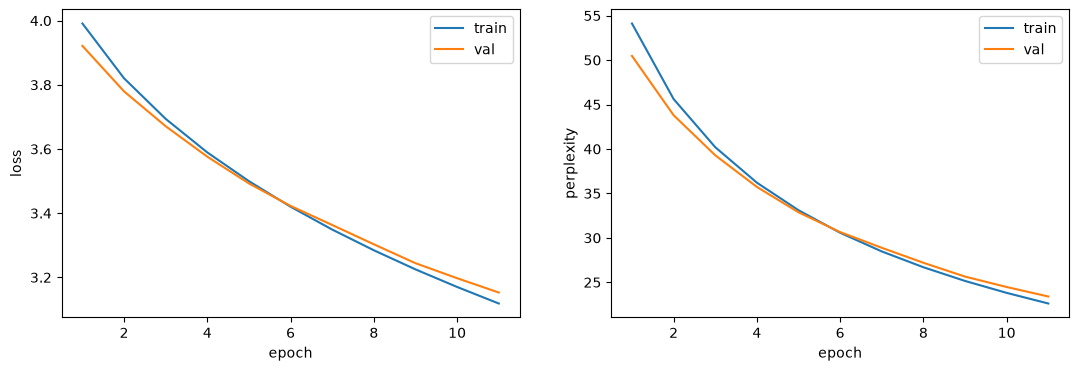

epoch #14


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 13.93it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50', '3.42', '3.35', '3.28', '3.22', '3.17', '3.12', '3.07']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49', '3.42', '3.36', '3.30', '3.24', '3.20', '3.15', '3.10']


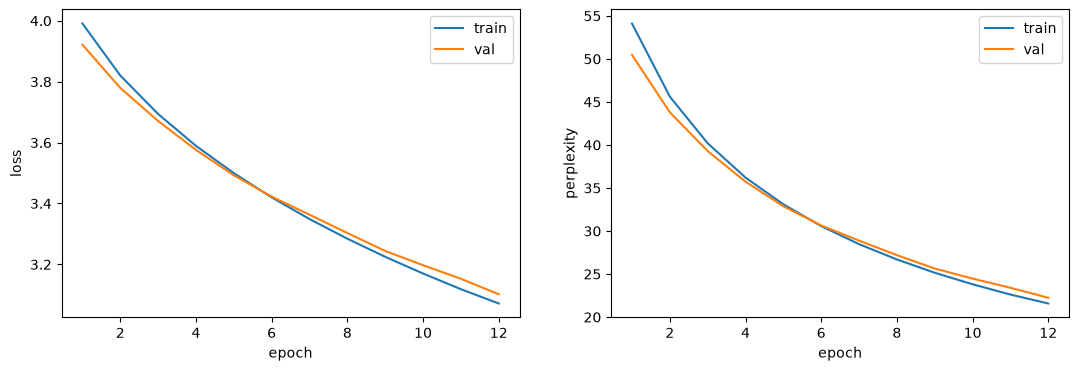

epoch #15


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 14.06it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50', '3.42', '3.35', '3.28', '3.22', '3.17', '3.12', '3.07', '3.03']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49', '3.42', '3.36', '3.30', '3.24', '3.20', '3.15', '3.10', '3.07']


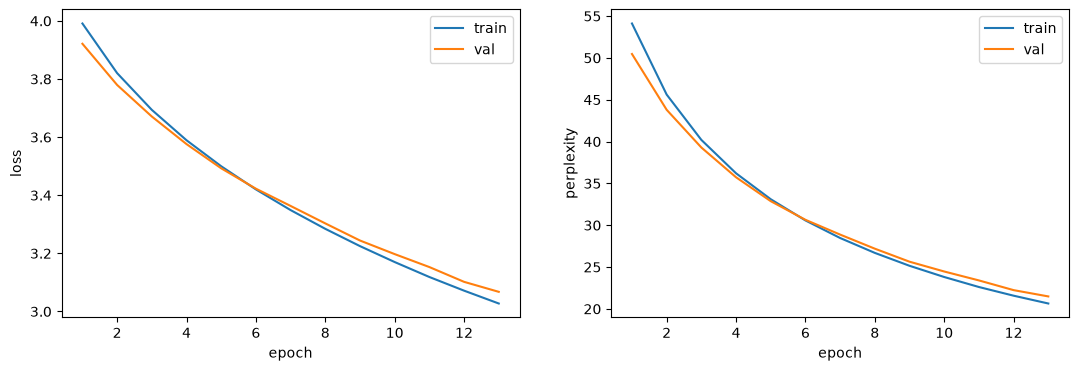

epoch #16


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 14.09it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50', '3.42', '3.35', '3.28', '3.22', '3.17', '3.12', '3.07', '3.03', '2.99']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49', '3.42', '3.36', '3.30', '3.24', '3.20', '3.15', '3.10', '3.07', '3.03']


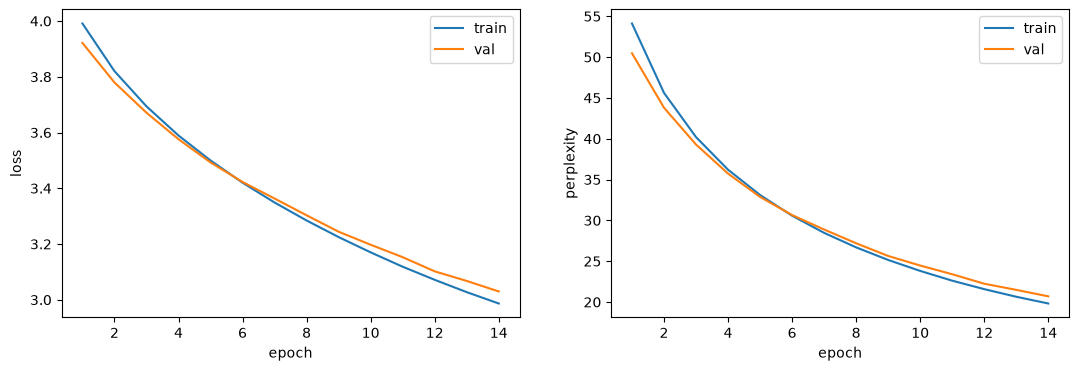

In [ ]:
epochs = 12
for epoch in range(epochs):
    print(f'epoch #{len(train_losses) + 1}')
    train_loss = training_epoch(model=model, optimizer=optimizer, data_loader=train_loader, criterion=criterion)
    val_loss = training_epoch(model=model, optimizer=optimizer, data_loader=val_loader, criterion=criterion)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    print([f'{num:.2f}' for num in train_losses])
    print([f'{num:.2f}' for num in val_losses])
    plot_losses(train_losses[2:], val_losses[2:])

epoch #25


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 15.96it/s]

['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50', '3.42', '3.35', '3.28', '3.22', '3.17', '3.12', '3.07', '3.03', '2.99', '2.95', '2.91', '2.88', '2.85', '2.82', '2.79', '2.76', '2.73', '2.71']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49', '3.42', '3.36', '3.30', '3.24', '3.20', '3.15', '3.10', '3.07', '3.03', '3.00', '2.96', '2.93', '2.90', '2.87', '2.85', '2.82', '2.79', '2.77']


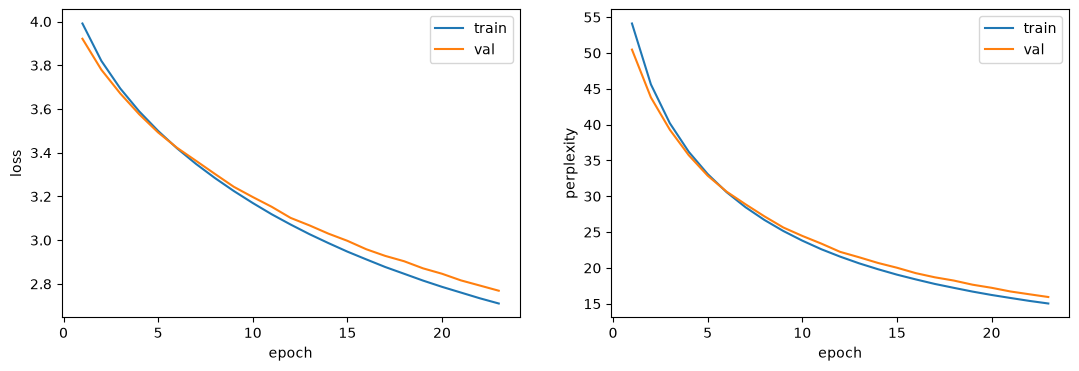

epoch #26


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 15.99it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50', '3.42', '3.35', '3.28', '3.22', '3.17', '3.12', '3.07', '3.03', '2.99', '2.95', '2.91', '2.88', '2.85', '2.82', '2.79', '2.76', '2.73', '2.71', '2.69']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49', '3.42', '3.36', '3.30', '3.24', '3.20', '3.15', '3.10', '3.07', '3.03', '3.00', '2.96', '2.93', '2.90', '2.87', '2.85', '2.82', '2.79', '2.77', '2.75']


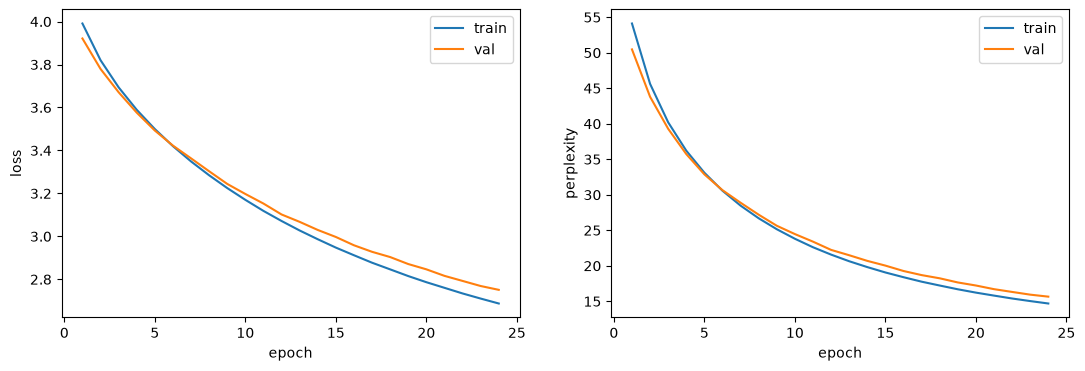

epoch #27


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 15.58it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50', '3.42', '3.35', '3.28', '3.22', '3.17', '3.12', '3.07', '3.03', '2.99', '2.95', '2.91', '2.88', '2.85', '2.82', '2.79', '2.76', '2.73', '2.71', '2.69', '2.67']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49', '3.42', '3.36', '3.30', '3.24', '3.20', '3.15', '3.10', '3.07', '3.03', '3.00', '2.96', '2.93', '2.90', '2.87', '2.85', '2.82', '2.79', '2.77', '2.75', '2.73']


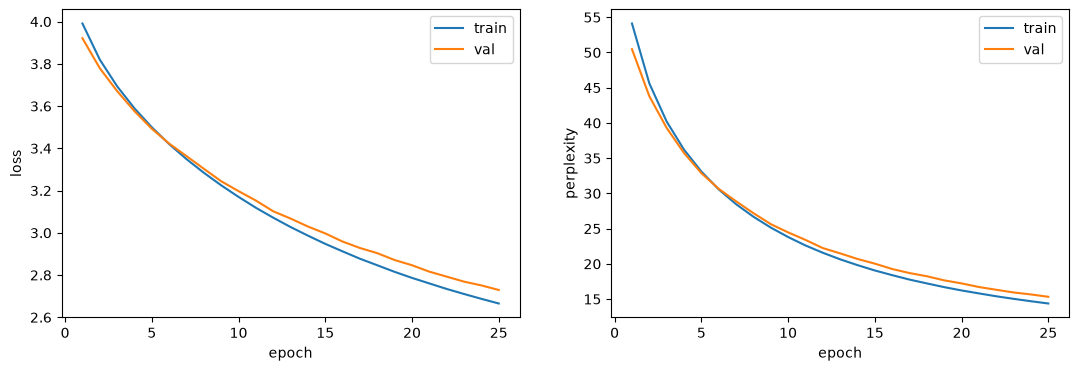

epoch #28


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 15.49it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50', '3.42', '3.35', '3.28', '3.22', '3.17', '3.12', '3.07', '3.03', '2.99', '2.95', '2.91', '2.88', '2.85', '2.82', '2.79', '2.76', '2.73', '2.71', '2.69', '2.67', '2.64']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49', '3.42', '3.36', '3.30', '3.24', '3.20', '3.15', '3.10', '3.07', '3.03', '3.00', '2.96', '2.93', '2.90', '2.87', '2.85', '2.82', '2.79', '2.77', '2.75', '2.73', '2.71']


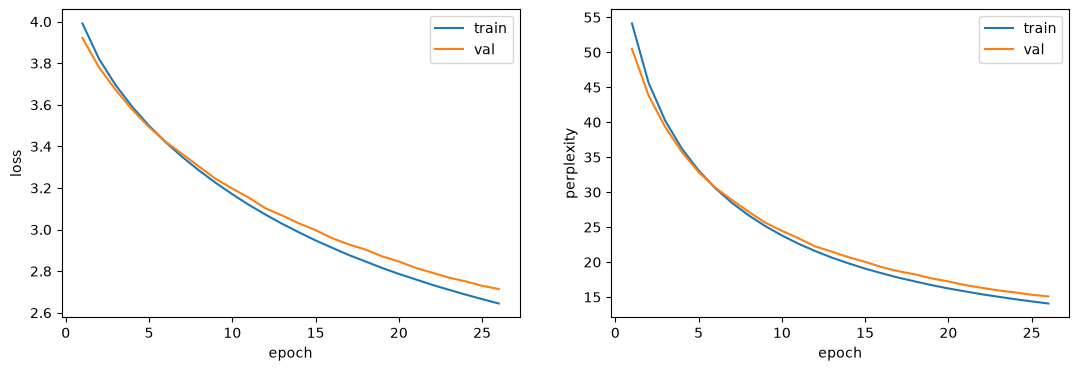

epoch #29


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 15.82it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50', '3.42', '3.35', '3.28', '3.22', '3.17', '3.12', '3.07', '3.03', '2.99', '2.95', '2.91', '2.88', '2.85', '2.82', '2.79', '2.76', '2.73', '2.71', '2.69', '2.67', '2.64', '2.62']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49', '3.42', '3.36', '3.30', '3.24', '3.20', '3.15', '3.10', '3.07', '3.03', '3.00', '2.96', '2.93', '2.90', '2.87', '2.85', '2.82', '2.79', '2.77', '2.75', '2.73', '2.71', '2.69']


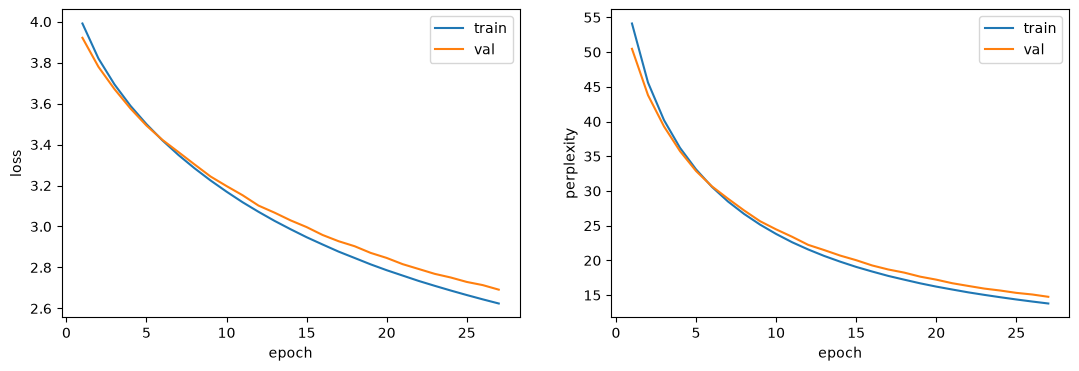

epoch #30


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 14.79it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50', '3.42', '3.35', '3.28', '3.22', '3.17', '3.12', '3.07', '3.03', '2.99', '2.95', '2.91', '2.88', '2.85', '2.82', '2.79', '2.76', '2.73', '2.71', '2.69', '2.67', '2.64', '2.62', '2.61']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49', '3.42', '3.36', '3.30', '3.24', '3.20', '3.15', '3.10', '3.07', '3.03', '3.00', '2.96', '2.93', '2.90', '2.87', '2.85', '2.82', '2.79', '2.77', '2.75', '2.73', '2.71', '2.69', '2.68']


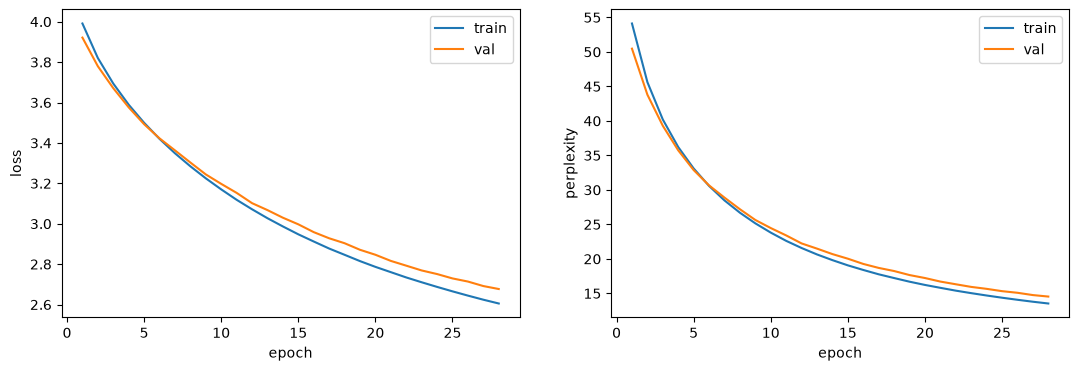

epoch #31


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 15.52it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50', '3.42', '3.35', '3.28', '3.22', '3.17', '3.12', '3.07', '3.03', '2.99', '2.95', '2.91', '2.88', '2.85', '2.82', '2.79', '2.76', '2.73', '2.71', '2.69', '2.67', '2.64', '2.62', '2.61', '2.59']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49', '3.42', '3.36', '3.30', '3.24', '3.20', '3.15', '3.10', '3.07', '3.03', '3.00', '2.96', '2.93', '2.90', '2.87', '2.85', '2.82', '2.79', '2.77', '2.75', '2.73', '2.71', '2.69', '2.68', '2.65']


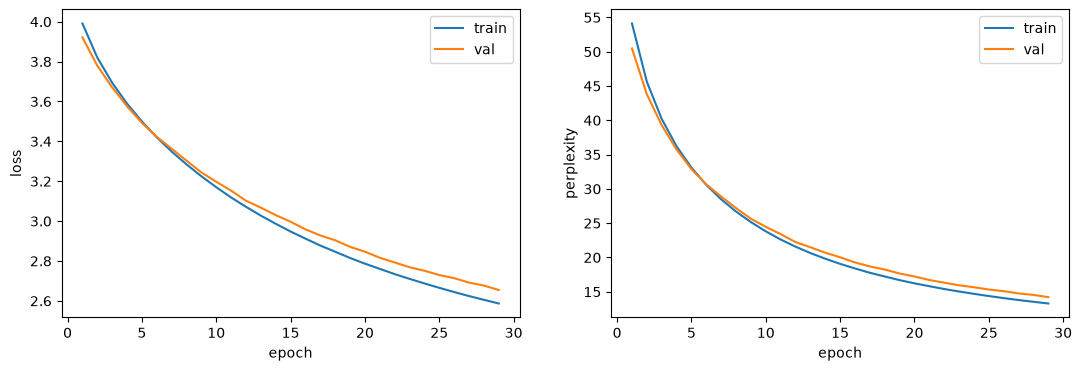

epoch #32


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 14.32it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50', '3.42', '3.35', '3.28', '3.22', '3.17', '3.12', '3.07', '3.03', '2.99', '2.95', '2.91', '2.88', '2.85', '2.82', '2.79', '2.76', '2.73', '2.71', '2.69', '2.67', '2.64', '2.62', '2.61', '2.59', '2.57']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49', '3.42', '3.36', '3.30', '3.24', '3.20', '3.15', '3.10', '3.07', '3.03', '3.00', '2.96', '2.93', '2.90', '2.87', '2.85', '2.82', '2.79', '2.77', '2.75', '2.73', '2.71', '2.69', '2.68', '2.65', '2.64']


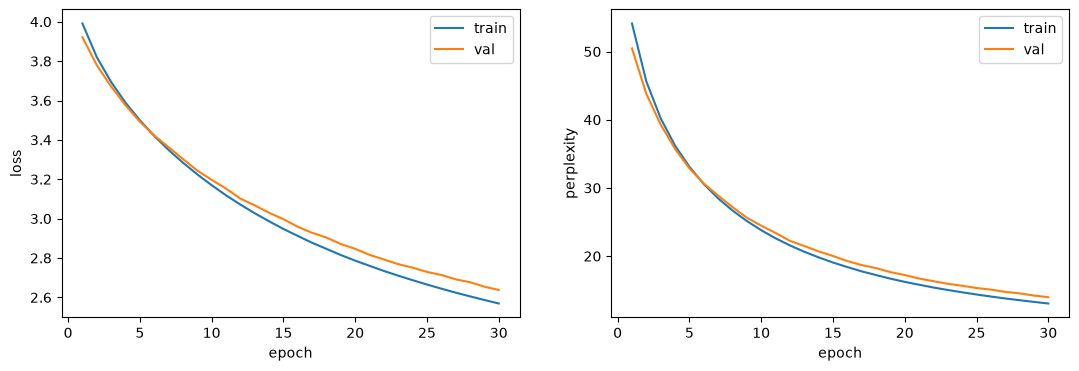

epoch #33


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 14.21it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50', '3.42', '3.35', '3.28', '3.22', '3.17', '3.12', '3.07', '3.03', '2.99', '2.95', '2.91', '2.88', '2.85', '2.82', '2.79', '2.76', '2.73', '2.71', '2.69', '2.67', '2.64', '2.62', '2.61', '2.59', '2.57', '2.55']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49', '3.42', '3.36', '3.30', '3.24', '3.20', '3.15', '3.10', '3.07', '3.03', '3.00', '2.96', '2.93', '2.90', '2.87', '2.85', '2.82', '2.79', '2.77', '2.75', '2.73', '2.71', '2.69', '2.68', '2.65', '2.64', '2.63']


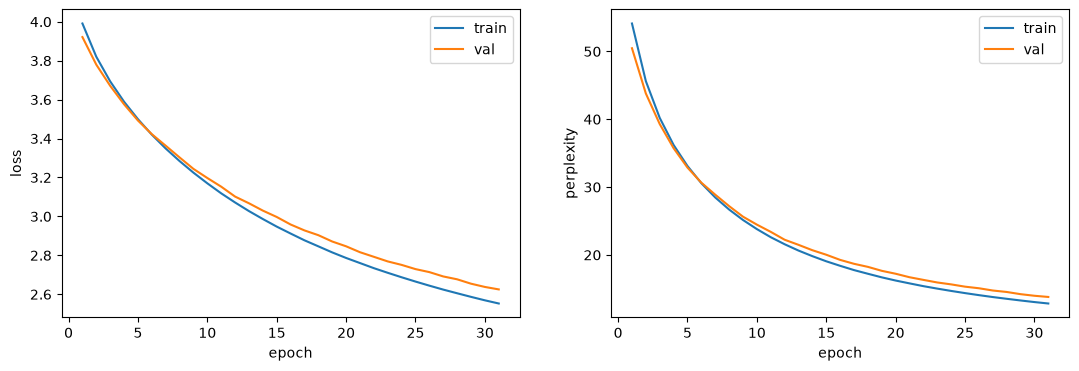

epoch #34


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 14.24it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50', '3.42', '3.35', '3.28', '3.22', '3.17', '3.12', '3.07', '3.03', '2.99', '2.95', '2.91', '2.88', '2.85', '2.82', '2.79', '2.76', '2.73', '2.71', '2.69', '2.67', '2.64', '2.62', '2.61', '2.59', '2.57', '2.55', '2.54']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49', '3.42', '3.36', '3.30', '3.24', '3.20', '3.15', '3.10', '3.07', '3.03', '3.00', '2.96', '2.93', '2.90', '2.87', '2.85', '2.82', '2.79', '2.77', '2.75', '2.73', '2.71', '2.69', '2.68', '2.65', '2.64', '2.63', '2.61']


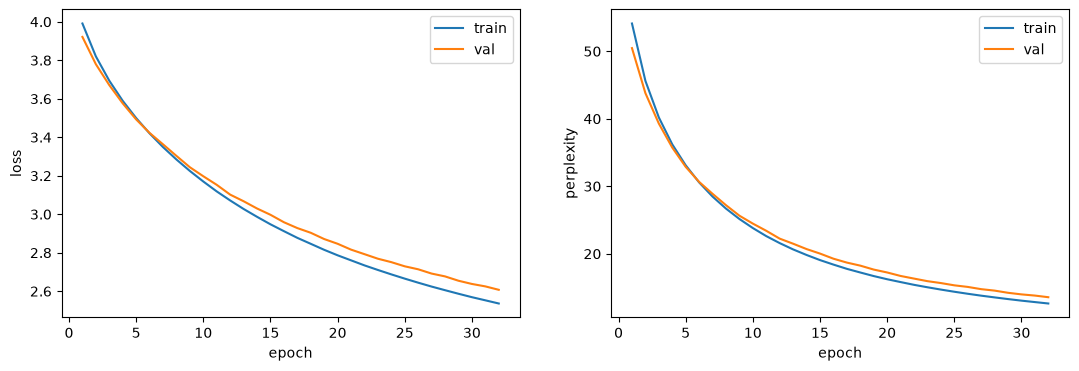

epoch #35


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 14.28it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50', '3.42', '3.35', '3.28', '3.22', '3.17', '3.12', '3.07', '3.03', '2.99', '2.95', '2.91', '2.88', '2.85', '2.82', '2.79', '2.76', '2.73', '2.71', '2.69', '2.67', '2.64', '2.62', '2.61', '2.59', '2.57', '2.55', '2.54', '2.52']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49', '3.42', '3.36', '3.30', '3.24', '3.20', '3.15', '3.10', '3.07', '3.03', '3.00', '2.96', '2.93', '2.90', '2.87', '2.85', '2.82', '2.79', '2.77', '2.75', '2.73', '2.71', '2.69', '2.68', '2.65', '2.64', '2.63', '2.61', '2.60']


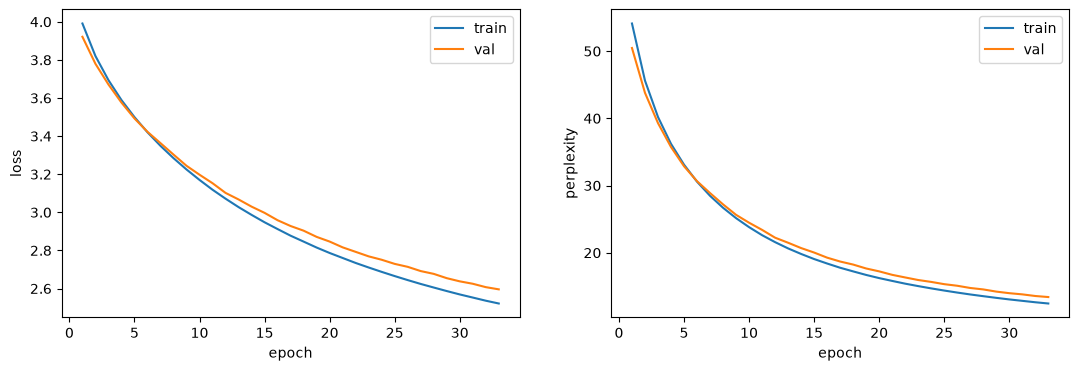

epoch #36


training_epoch: 100%|██████████| 48/48 [00:03<00:00, 14.27it/s]


['5.18', '4.27', '3.99', '3.82', '3.69', '3.59', '3.50', '3.42', '3.35', '3.28', '3.22', '3.17', '3.12', '3.07', '3.03', '2.99', '2.95', '2.91', '2.88', '2.85', '2.82', '2.79', '2.76', '2.73', '2.71', '2.69', '2.67', '2.64', '2.62', '2.61', '2.59', '2.57', '2.55', '2.54', '2.52', '2.51']
['4.54', '4.12', '3.92', '3.78', '3.67', '3.58', '3.49', '3.42', '3.36', '3.30', '3.24', '3.20', '3.15', '3.10', '3.07', '3.03', '3.00', '2.96', '2.93', '2.90', '2.87', '2.85', '2.82', '2.79', '2.77', '2.75', '2.73', '2.71', '2.69', '2.68', '2.65', '2.64', '2.63', '2.61', '2.60', '2.58']


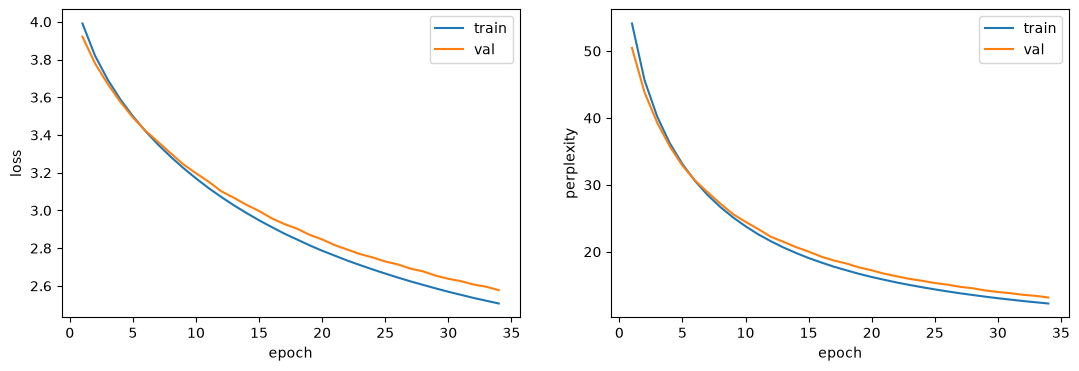

In [ ]:
epochs = 12
for epoch in range(epochs):
    print(f'epoch #{len(train_losses) + 1}')
    train_loss = training_epoch(model=model, optimizer=optimizer, data_loader=train_loader, criterion=criterion)
    val_loss = training_epoch(model=model, optimizer=optimizer, data_loader=val_loader, criterion=criterion)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    print([f'{num:.2f}' for num in train_losses])
    print([f'{num:.2f}' for num in val_losses])
    plot_losses(train_losses[2:], val_losses[2:])

In [ ]:
torch.save(model.state_dict(), f'gpt2_256-8-4-swiglu_untied.state_dict')

### inference

In [ ]:
def generate(model, start=''):
    model.eval()
    text = start.strip()
    tokenizer = train_set
    tokens = tokenizer.text2ids(text) if text else [train_set.bos_id]
    print(end=tokenizer.ids2text(tokens))

    line_length = len(tokenizer.ids2text(tokens))
    for i in range(128):
        with torch.no_grad():
            logits = model(torch.as_tensor([tokens]).to(DEVICE))

        t = torch.tensor(sorted(enumerate(logits[0, -1, :].data.cpu().numpy()), key=lambda x: -x[1]))[:100]
        probs = torch.softmax(t[:, 1], dim=-1)
        next_token_index = np.random.choice(len(probs), p=probs.numpy())
        next_token_index = t[next_token_index][0]

        next_piece = train_set.sp_model.id_to_piece(int(next_token_index)).replace('▁', ' ')
        tokens.append(int(next_token_index))
        if next_token_index == train_set.eos_id:
            break
        next_token = tokenizer.ids2text(tokens[-1])
        print(end=next_piece)
        # print(end=next_token)
        line_length += len(next_token)
        # if line_length > 100:
        #   line_length = 0
    print()
    return train_set.ids2text(tokens)

for i in range(1):
    result = generate(model, start='жена')

жена - улучнувшись к себе свистую и говорит - я тебя ищу ненавижу.
